In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from capstone_methods import *

import warnings
warnings.filterwarnings('ignore')

In [2]:
%matplotlib inline

In [3]:
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)

In [4]:
file = pd.ExcelFile('/Users/courtneystenstrom/Code/Capstone/Excel Files/foreveralone.xlsx')
df = pd.read_excel(file, 'Sheet1')

In [5]:
df_org = df.copy()

## Exploratory Data Analysis

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   gender                 636 non-null    object
 1   sexuality              636 non-null    object
 2   age                    636 non-null    int64 
 3   income                 636 non-null    object
 4   race                   636 non-null    object
 5   bodyweight             636 non-null    object
 6   virgin                 636 non-null    object
 7   prostitution_legal     636 non-null    object
 8   pay_for_sex            636 non-null    object
 9   friends                636 non-null    int64 
 10  social_fear            636 non-null    object
 11  depressed              636 non-null    object
 12  what_help_from_others  636 non-null    object
 13  attempt_suicide        636 non-null    object
 14  employment             636 non-null    object
 15  education              

In [7]:
df.describe()

,age,friends
count,636.000000,636.000000
mean,23.963836,5.259434
std,5.934308,5.476391
min,12.000000,0.000000
25%,20.000000,1.000000
50%,23.000000,4.000000
75%,27.000000,7.000000
max,70.000000,40.000000


In [8]:
df.head(10)

,gender,sexuality,age,income,race,bodyweight,virgin,prostitution_legal,pay_for_sex,friends,social_fear,depressed,what_help_from_others,attempt_suicide,employment,education,improve_yourself_how
0,Male,Straight,17,0,White non-Hispanic,Underweight,Yes,No,Yes but I haven't,6,Yes,Yes,"wingman/wingwoman, date coaching",No,A student,High school graduate / GED,Therapy
1,Male,Straight,21,0,Native American,Normal weight,Yes,Yes,Yes but I haven't,10,Yes,No,Just want mates that make it look like I fit in,No,A student,Bachelor's Degree,"Joined a gym/go to the gym, join clubs/socual ..."
2,Female,Straight,22,0,Asian,Normal weight,Yes,Yes,No,0,Yes,Yes,Set me up with a date,No,Out of work but not currently looking for work,"Some college, no degree",Joined a gym/go to the gym
3,Female,Straight,23,0,White non-Hispanic,Underweight,Yes,No,No,10,Yes,Yes,I don't want help,No,Out of work but not currently looking for work,Associate degree,None
4,Female,Straight,31,"$20,000 to $29,999",White non-Hispanic,Normal weight,No,No,No,4,Yes,Yes,I don't want help,No,Employed for wages,"Some college, no degree",None
5,Female,Gay/Lesbian,35,"$1 to $10,000",Black,Obese,No,No,No,3,Yes,Yes,"wingman/wingwoman, Set me up with a date",No,Out of work but not currently looking for work,"Some college, no degree","Therapy, join clubs/socual clubs/meet ups"
6,Male,Straight,25,0,White non-Hispanic,Underweight,Yes,No,No,0,Yes,Yes,"wingman/wingwoman, Set me up with a date, date...",Yes,A student,"Some college, no degree","Joined a gym/go to the gym, Therapy, Other exe..."
7,Male,Straight,20,"$1 to $10,000",White non-Hispanic,Normal weight,Yes,Yes,No,20,Yes,No,I don't want help,No,A student,"Some college, no degree",Other exercise
8,Male,Straight,29,"$75,000 or more",Black,Overweight,Yes,No,Yes but I haven't,2,Yes,Yes,not sure what would help,Yes,Self-employed,"Some college, no degree","Joined a gym/go to the gym, Therapy, Other exe..."
9,Male,Straight,25,0,White non-Hispanic,Normal weight,No,Yes,Yes and I have,7,No,No,I don't want help,No,A student,High school graduate / GED,"Joined a gym/go to the gym, Other exercise"


In [9]:
columns = ['gender', 'sexuality', 'race', 'bodyweight', 'employment', 'education']

for column in columns:
    print('{} : {}'.format(column, df[column].unique().tolist()))
    print()

gender : ['Male', 'Female']

sexuality : ['Straight', 'Gay/Lesbian', 'Bisexual']

race : ['White non-Hispanic', 'Native American', 'Asian', 'Black', 'Hispanic (of any race)', 'Mixed Race']

bodyweight : ['Underweight', 'Normal weight', 'Obese', 'Overweight']

employment : ['A student', 'Out of work but not currently looking for work', 'Employed for wages', 'Self-employed', 'Out of work and looking for work', 'Retired', 'Unable to work', 'Military', 'A homemaker']

education : ['High school graduate / GED', "Bachelor's Degree", 'Some college, no degree', 'Associate degree', 'Masters Degree or Higher', 'Some high school, no diploma', 'Trade/technical/vocational training']



In [10]:
for column in columns:
    print(df[column].value_counts())
    print()

Male      472
Female    164
Name: gender, dtype: int64

Straight       556
Bisexual        64
Gay/Lesbian     16
Name: sexuality, dtype: int64

White non-Hispanic        462
Asian                      67
Hispanic (of any race)     47
Black                      33
Mixed Race                 18
Native American             9
Name: race, dtype: int64

Normal weight    375
Overweight       152
Underweight       74
Obese             35
Name: bodyweight, dtype: int64

A student                                         236
Employed for wages                                223
Out of work and looking for work                   59
Out of work but not currently looking for work     53
Self-employed                                      27
Unable to work                                     26
Military                                            6
Retired                                             3
A homemaker                                         3
Name: employment, dtype: int64

Some college, no

### Encoding Categorical Data

#### Ordinal Data:

In [11]:
income_dict = {'$0' : 0,
               '$1 to $10,000' : 1,
               '$10,000 to $19,999' : 2,
               '$20,000 to $29,999' : 3,
               '$30,000 to $39,999' : 4,
               '$40,000 to $49,999' : 5,
               '$50,000 to $74,999' : 6,
               '$75,000 or more' : 7
              }

df.replace({'income' : income_dict}, inplace=True)

In [12]:
edu_dict = {'Some high school, no diploma' : 0,
            'High school graduate / GED' : 1,
            'Trade/technical/vocational training' : 2,
            'Some college, no degree' : 3,
            'Associate degree' : 4,
            'Bachelor\'s Degree' : 5,
            'Masters Degree or Higher' : 6
           }

df.replace({'education' : edu_dict}, inplace=True)

In [13]:
df['bodyweight'] = df['bodyweight'].map({'Underweight' : 0,
                                         'Normal weight' : 1,
                                         'Overweight' : 2,
                                         'Obese' : 3})

#### Nominal Data:

In [14]:
df['gender'] = df['gender'].map({'Male' : 1, 'Female' : 0})

In [15]:
df['employment'] = df['employment'].astype('category')

df['employment'] = df['employment'].cat.codes

In [16]:
df['race'] = df['race'].astype('category')
df['race'] = df['race'].cat.codes

In [17]:
df['sexuality'] = df['sexuality'].astype('category')

df['sexuality'] = df['sexuality'].cat.codes

In [18]:
df['pay_for_sex'] = df['pay_for_sex'].map({'No' : 0,
                                          'Yes but I haven\'t' : 1,
                                          'Yes and I have' : 2})

#### Other Data:

The formatting of this column is not great from an analytic point of view.  The option to check off as many or as few options that apply leaves many single values.  To work with this, I'm going to break it down into how many things a person has done to try and improve themselves, if any at all.

In [19]:
df['total_improves'] = df['improve_yourself_how'].str.split(',').apply(lambda x: len([i for i in x if i != 'None'])) 

---

In [20]:
df = df[df['friends'] <= 20]
df['friends'] = df['friends'].astype('int')

In [21]:
def sort_friends(x):
    if 0 <= x < 5:
        return 0
    if 5 <= x < 10:
        return 1
    if 10 <= x < 15:
        return 2
    if 15 <= x < 20:
        return 3
    if x >= 20:
        return 4

In [22]:
df['friend_bin'] = df['friends'].apply(sort_friends)

---

Because of formatting issues from the column what_help_from_others, I created a column that distinguished between whether the respondent was open to help from those in their life.

In [23]:
def help_or_no(x):
    '''
    INPUT: One value from the column what help from others
    OUTPUT: 0 if response was I dont want help
            1 if response included any combination of items signaling desire of external help from others
    '''
    
    if x == 'I don\'t want help':
        return 0
    else:
        return 1
    

In [24]:
df['open_to_help'] = df['what_help_from_others'].apply(help_or_no)

---

In [25]:
def sort_age(x):
    if 0 <= x <= 19:
        return 0
    elif 20 <= x <= 39:
        return 1
    elif x >= 40:
        return 2

In [26]:
df['age_bin'] = df['age'].apply(sort_age)

---

Encoding the last of the string variables, this will encode the values of columns such as depressed, suicide_attempt, and virgin

In [27]:
df.replace({'No' : 0, 'Yes' : 1}, inplace=True)

In [28]:
df_binary = df[['gender', 'virgin', 'depressed', 'social_fear', 'attempt_suicide', 'open_to_help']]

### Visualizations

<AxesSubplot:xlabel='age', ylabel='count'>

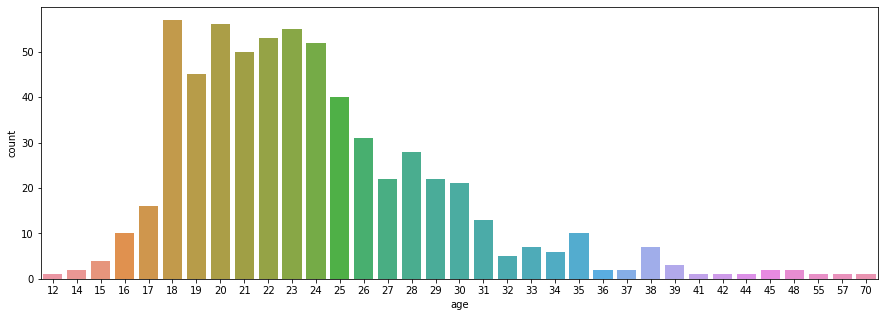

In [29]:
plt.figure(figsize=(15,5))
sns.countplot('age', data=df)

<AxesSubplot:xlabel='income', ylabel='count'>

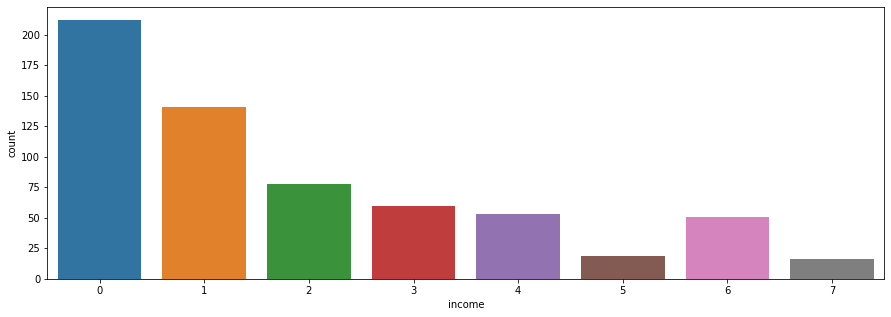

In [30]:
plt.figure(figsize=(15,5))
sns.countplot('income', data=df)

<AxesSubplot:xlabel='friends', ylabel='Count'>

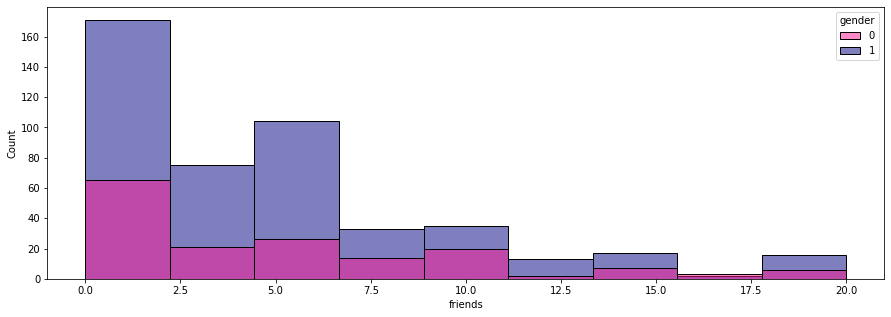

In [52]:
plt.figure(figsize=(15,5))
custom_pal = ['deeppink', 'navy']
sns.set_palette(custom_pal)
sns.histplot(data=df, x='friends', hue='gender', bins=9)

<AxesSubplot:xlabel='attempt_suicide', ylabel='count'>

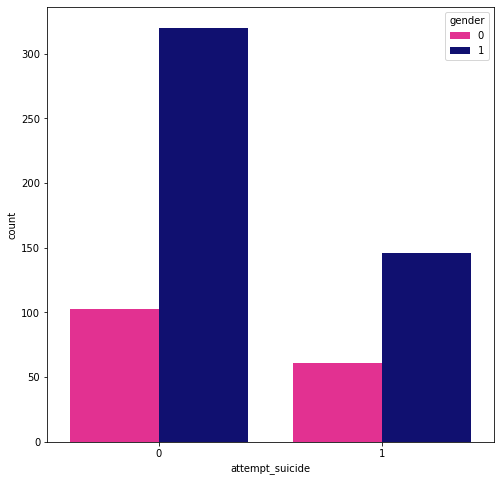

In [54]:
plt.figure(figsize=(8,8))
sns.countplot('attempt_suicide', hue='gender', data=df)

In [ ]:
df.drop(['what_help_from_others', 'improve_yourself_how', 'age', 'friends', 'pay_for_sex', 'prostitution_legal'], axis=1, inplace=True)

In [ ]:
df.rename({'friend_bin' : 'friends', 'age_bin' : 'age'}, inplace = True)

## Frequency Counts

Frequency Count tables are a way to explore the frequency and percentage distribution of categorical variables, and those counts are necessary to obtain for the chi square tests.

In [ ]:
def freq_table(column1, column2):
    '''
    Input: two columns
    Output: frequency counts between the two columns'''
    tab = pd.crosstab(index=column1,
                     columns=column2)
    
    print(tab)
    
    return

In [ ]:
from scipy.stats import chi2_contingency

def chi_test(counts):
    '''
    calculates the pvalue, chi statistic, and whether the variables are independent or dependent
    measuring on a significance level of 5% 
    
    Independent : the variables have
    INPUT: the associated frequency count variables in an array of arrays
    OUTPUT: Pvalue, Chi Statistic, Variable dependency / independency
            '''
    stat, p, dof, expected = chi2_contingency(counts, correction=False)
    print('P-value is: ' + str(p))
    print('Chi Statistic is: ' + str(stat))
    if p <= 0.05:
        print('There is an association between variables')
    else:
        print('No association ')
    return stat


In [ ]:
def cramerStat(data, stat):
    n = np.sum(data)
    md = min(data.shape) - 1

    V = np.sqrt((stat/n) / md)

    print(V)
    
    if V <= 0.2:
        print('Weak')
    elif 0.2 < V <= 0.6:
        print('Moderate')
    elif V > 0.6:
        print('Strong')
    
    return

## Frequency Tables and Chi Square Tests

H0 - There is no association between the variables (Independent) </br>
H1 - There is an association between the variables (Dependent) </br>
</br>
A result as dependent allows us to reject the null hypothesis in saying there is some type of association or relationship between variables.  

### Gender Relationships

**Gender and Depression**

In [ ]:
freq_table(df.depressed, df.gender)

In [ ]:
data = np.array([[62,156], [102,310]])

stat = chi_test(data)

**Gender and Sexuality**

In [ ]:
freq_table(df.sexuality, df.gender)

In [ ]:
data = np.array([[37, 24], [7, 8], [120, 434]])

stat = chi_test(data)

In [ ]:
cramerStat(data, stat)

**Gender and Employment**

In [ ]:
freq_table(df.gender, df.employment)

In [ ]:
data = np.array([[2,60,55,1,15,14,0,6,11],[1,175,165,5,44,37,3,21,15]])

stat = chi_test(data)

**Gender and Race**

In [ ]:
freq_table(df.gender, df.race)

In [ ]:
data = np.array([[19,13,15,6,0,111], [48,20,32,12,9,345]])

stat = chi_test(data)

**Gender and Income**

In [ ]:
freq_table(df.gender, df.income)

In [ ]:
data = np.array([[55,33,19,22,7,8,16,1,0,2,0,1,0], [157,108,59,38,46,11,26,8,3,5,2,1,2]])

stat = chi_test(data)

### Depression Relationships

**Depression and Social Fear**

In [ ]:
freq_table(df.social_fear, df.depressed)

In [ ]:
data = np.array([[114,89],[104,323]])

stat = chi_test(data)

In [ ]:
cramerStat(data,stat)

**Depression and Employment**

In [ ]:
freq_table(df.depressed, df.employment)

In [ ]:
data = np.array([[1,88,79,4,14,12,0,14,6],[2,147,141,2,45,39,3,13,20]])

stat = chi_test(data)

In [ ]:
cramerStat(data,stat)

**Depression and Friends**

In [ ]:
freq_table(df.friend_bin, df.depressed)

In [ ]:
data = np.array([[78,254],[76,111], [27,33], [23,8], [14,6]])

stat = chi_test(data)

In [ ]:
cramerStat(data, stat)

**Depression and Bodyweight**

In [ ]:
freq_table(df.depressed, df.bodyweight)

In [ ]:
data = np.array([[21,152,38,7],[51,220,113,28]])

stat = chi_test(data)

In [ ]:
cramerStat(data, stat)

**Depression and Education**

In [ ]:
freq_table(df.depressed, df.education)

In [ ]:
data = np.array([[20,39,8,62,8,67,14],[47,92,14,130,17,84,28]])

stat = chi_test(data)

### Social Fear Relationships

**Social Fear and Friends**

In [ ]:
freq_table(df.social_fear, df.friend_bin)

In [ ]:
data = np.array([[82,56,27,25,13], [250,131,33,6,7]])

stat = chi_test(data)

In [ ]:
cramerStat(data, stat)

**Sexuality and Bodyweight**

In [ ]:
freq_table(df.sexuality, df.bodyweight)

In [ ]:
data = np.array([[7,39,8,7], [0,8,4,3], [65,325,139,25]])

stat = chi_test(data)

In [ ]:
cramerStat(data, stat)

## Selecting Data

#### Calculating VIF

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(x):
    vif = pd.DataFrame()
    vif['variables'] = x.columns
    vif['VIF'] = [variance_inflation_factor(x.values, i) for i in range(x.shape[1])]
    
    return vif

In [ ]:
from sklearn.model_selection import train_test_split

y = df['attempt_suicide']
X = df.drop(['attempt_suicide', 'virgin'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 21, test_size=0.2)

In [ ]:
calculate_vif(X)

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2

select = SelectKBest(chi2, k='all')
select.fit_transform(X, y)

cols = select.get_support(indices=True)
feat_new = df.iloc[:,cols]

ln = feat_new.columns.tolist()

In [ ]:
l = select.scores_.tolist()
data = {'Var' : ln, 'Score' : l}

pd.DataFrame(data).sort_values(by='Score', ascending=False)

In [ ]:
def heatmap_data(data, method):
    """
    Takes data passed and determines coorelation, creates mask,
    and shows resulting plot
    """

    corr = data.corr(method=method)
    mask = np.zeros_like(corr)
    mask[np.triu_indices_from(mask)] = True
    with sns.axes_style('white'):
        f, ax = plt.subplots(figsize=(15,15))
        ax = sns.heatmap(corr, mask=mask, annot=True, lw=1, linecolor='white', cmap='viridis')
        plt.title('Correlation')
        plt.xticks(rotation=60)
        plt.yticks(rotation=60)
    plt.show()
    

In [ ]:
ordinal_vars = df[['income', 'bodyweight', 'education', 'age_bin', 'friend_bin']]

In [ ]:
heatmap_data(df_binary, 'spearman')

In [ ]:
heatmap_data(df, 'spearman')

In [ ]:
df.to_excel('selected.xlsx')

## Log Loss Values

In [ ]:
from sklearn.metrics import log_loss

logloss_A = log_loss(y_test, model_A.predict_proba(X_test))
logloss_B = log_loss(y_test, model_B.predict_proba(X_test))
logloss_C = log_loss(y_test, model_C.predict_proba(X_test))

In [ ]:
logloss_A

In [ ]:
logloss_B

In [ ]:
logloss_C